# Projeto: Comprar BTC usando HI-LO


Desafio: Comprar BTC usando o indicador HI-LO Activator pra ficar fora do mercado em grandes quedas.


### Passo a passo:

   **Passo 1** - Importar bibliotecas
   
   **Passo 2** - Pegar dados de cotação do Yahoo Finance
   
   **Passo 3** - Preparar e calcular dados importantes pro modelo
   
   **Passo 4** - Gerar sinais de compra
   
   **Passo 5** - Gerar sinais de venda

   **Passo 6** - Gerar operações
   
   **Passo 7** - Criar um ID para todos os trades históricos na tabela
   
   **Passo 8** - Calcular retornos de todos os trades

   
   <br>
   
   
-------------------

# Passo 1 - Importar as bibliotecas

In [ ]:
import yfinance
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import mplcyberpunk
plt.style.use("cyberpunk")

# Passo 2 - Pegar dados de cotação do Yahoo Finance

In [ ]:
ticker = "BTC-USD"

In [ ]:
dados = yf.download(ticker, auto_adjust = False)
dados

# Passo 3 - Preparar e calcular dados importantes pro modelo

In [ ]:
dados["retorno"] = dados["Adj Close"].pct_change()
dados_retornos_completos = dados["retorno"]

dados

In [ ]:
dados["media_maxima"] = dados["High"].rolling(window = 20).mean()
dados["media_minima"] = dados["Low"].rolling(window = 20).mean()

dados

In [ ]:
dados = dados.droplevel(1, axis = 1)
dados

# Passo 4 - Gerar sinais de compra

In [ ]:
dados["sinal_compra"] = 0
dados["sinal_compra"] = (dados["Close"] > dados["media_maxima"]).astype(int)
dados

# Passo 5 - Gerar sinais de venda

In [ ]:
dados["sinal_venda"] = 0
dados["sinal_venda"] = (dados["Close"] < dados["media_minima"]).astype(int)

# Passo 6 - Gerar operações

In [ ]:
dados["posicao"] = 0

for i in range(1, len(dados)):

    if dados["sinal_compra"].iloc[i] == 1:

        dados["posicao"].iloc[i] = 1

    elif dados["sinal_venda"].iloc[i] == 1:

        dados["posicao"].iloc[i] = 0

    else:

        if (dados["posicao"].iloc[i - 1] == 1) and (dados["sinal_venda"].iloc[i] == 0):

            dados["posicao"].iloc[i] = 1

        else:

            dados["posicao"].iloc[i] = 0

In [ ]:
dados["posicao"] = dados["posicao"].shift()

dados

# Passo 7 - Criar um ID para todos os trades históricos na tabela

In [ ]:
dados["trades"] = (dados["posicao"] != dados["posicao"].shift()).cumsum()

dados

In [ ]:
dados["trades"] = dados["trades"].where(dados["posicao"] == 1)

dados

In [ ]:
dados = dados.dropna()

# Passo 8 - Calcular retornos de todos os trades

In [ ]:
tabela_retorno_acumulado = (1 + dados["retorno"]).cumprod() - 1

tabela_retorno_acumulado

Date
2014-10-14      0.026782
2014-10-15      0.011165
2014-10-16     -0.020127
2014-10-17     -0.017049
2014-10-18      0.002633
                 ...    
2025-05-28    382.906586
2025-05-29    375.212344
2025-05-30    369.360611
2025-06-10    369.236813
2025-06-11    364.415209
Name: retorno, Length: 2194, dtype: float64

In [ ]:
dados_retornos_completos_acum = (1 + dados_retornos_completos).cumprod() - 1

In [ ]:
dados_retornos_completos_acum

Date
2014-09-17           NaN
2014-09-18     -0.071926
2014-09-19     -0.136745
2014-09-20     -0.105896
2014-09-21     -0.127944
                 ...    
2025-06-07    229.937611
2025-06-08    230.326875
2025-06-09    240.167501
2025-06-10    240.086888
2025-06-11    236.947207
Name: retorno, Length: 3921, dtype: float64

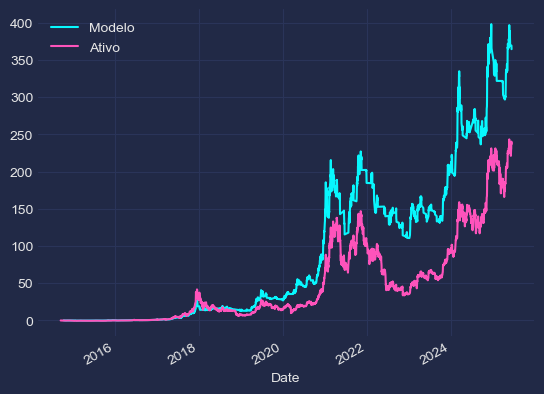

In [ ]:
tabela_retorno_acumulado.plot(label = "Modelo")
dados_retornos_completos_acum.plot(label = "Ativo")
plt.legend()